In [3]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
denue = pd.read_csv(
    "../Data/INEGI/denue_inegi_09_.csv",
    encoding="latin-1",
    low_memory=False
)

print("Dimensiones:", denue.shape)
print("\nColumnas:")
print(denue.columns.tolist())

Dimensiones: (460762, 42)

Columnas:
['id', 'clee', 'nom_estab', 'raz_social', 'codigo_act', 'nombre_act', 'per_ocu', 'tipo_vial', 'nom_vial', 'tipo_v_e_1', 'nom_v_e_1', 'tipo_v_e_2', 'nom_v_e_2', 'tipo_v_e_3', 'nom_v_e_3', 'numero_ext', 'letra_ext', 'edificio', 'edificio_e', 'numero_int', 'letra_int', 'tipo_asent', 'nomb_asent', 'tipoCenCom', 'nom_CenCom', 'num_local', 'cod_postal', 'cve_ent', 'entidad', 'cve_mun', 'municipio', 'cve_loc', 'localidad', 'ageb', 'manzana', 'telefono', 'correoelec', 'www', 'tipoUniEco', 'latitud', 'longitud', 'fecha_alta']


In [6]:
denue.head()

,id,clee,nom_estab,raz_social,codigo_act,nombre_act,per_ocu,tipo_vial,nom_vial,tipo_v_e_1,...,localidad,ageb,manzana,telefono,correoelec,www,tipoUniEco,latitud,longitud,fecha_alta
0,11845788,09013112515000091000000000U5,AJOLOTARIO APATLACO,NaN,112515,Piscicultura en agua dulce,0 a 5 personas,PRIVADA,Ninguno,PRIVADA,...,Apatlaco ...,1281,800,5.577368e+09,EDUARDOSANCHEVALDERRAMA@GMAIL.COM,NaN,Fijo,19.264524,-99.089505,2025-05
1,11845785,09013112515000071000000000U7,AJOLOTARIO CARRIZAL,NaN,112519,Otra acuicultura,0 a 5 personas,CERRADA,Ninguno,CERRADA,...,Paraje de la Ciénega,1281,800,5.526720e+09,NaN,NaN,Fijo,19.275685,-99.101824,2025-05
2,11845786,09013112515000082000000000U4,AJOLOTARIO CHINAMPA ONKALI,ONKALI SC DE RL,112519,Otra acuicultura,6 a 10 personas,OTRO(ESPECIFIQUE),Canal,CALLE,...,Xochimilco ...,1099,34,5.518275e+09,NaN,NaN,Fijo,19.277486,-99.097971,2025-05
3,11845789,09013112515000102000000000U0,AJOLOTARIO TLAZOCAMA TONANA,NaN,112519,Otra acuicultura,6 a 10 personas,OTRO(ESPECIFIQUE),Canal,CALLEJON,...,Xochimilco ...,1099,15,NaN,ORTADAVID294@GMAIL.COM,NaN,Fijo,19.274853,-99.101802,2025-05
4,11845781,09013112515000051000000000U9,AJOLOTERIA APANTLI,NaN,112519,Otra acuicultura,0 a 5 personas,PRIVADA,Ninguno,PRIVADA,...,Chililico ...,1281,800,5.561064e+09,JESUSC.AXOLOTL@GMAIL.COM,NaN,Fijo,19.265019,-99.090506,2025-05


In [7]:
columnas = [
    "id", "latitud", "longitud",
    "per_ocu", "codigo_act", "nombre_act"
]

denue = denue[columnas].copy()

print("Establecimientos:", len(denue))
print("IDs duplicados:", denue["id"].duplicated().sum())

print("\nValores faltantes:")
print(denue.isna().sum())

print("\nRangos de personal ocupado:")
print(denue["per_ocu"].value_counts())

Establecimientos: 460762
IDs duplicados: 0

Valores faltantes:
id            0
latitud       0
longitud      0
per_ocu       0
codigo_act    0
nombre_act    0
dtype: int64

Rangos de personal ocupado:
per_ocu
0 a 5 personas        393261
6 a 10 personas        30734
11 a 30 personas       22353
31 a 50 personas        5320
51 a 100 personas       4343
101 a 250 personas      2835
251 y más personas      1916
Name: count, dtype: int64


In [8]:
print(denue[["latitud", "longitud"]].describe())

denue_geo = gpd.GeoDataFrame(
    denue,
    geometry=gpd.points_from_xy(
        denue["longitud"],
        denue["latitud"]
    ),
    crs="EPSG:4326"
).to_crs(epsg=32614)

print("\nSistema de coordenadas:", denue_geo.crs)
print("Establecimientos georreferenciados:", len(denue_geo))

             latitud       longitud
count  460762.000000  460762.000000
mean       19.381594     -99.127270
std         0.076015       0.065366
min        19.114837     -99.354395
25%        19.329434     -99.168454
50%        19.382717     -99.129840
75%        19.435464     -99.084098
max        19.579874     -98.945228

Sistema de coordenadas: EPSG:32614
Establecimientos georreferenciados: 460762


In [10]:
estaciones = pd.read_csv(
    "../Data/Estaciones_ECOBICI/estaciones_ECOBICI.csv",
    encoding="latin-1"
)

print("Dimensiones:", estaciones.shape)
print("Columnas:", estaciones.columns.tolist())

estaciones.head()

Dimensiones: (989, 10)
Columnas: ['sistema', 'num_cicloe', 'calle_prin', 'calle_secu', 'colonia', 'alcaldia', 'latitud', 'longitud', 'sitio_de_e', 'estatus']


,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada


In [11]:
estaciones = estaciones.dropna(
    subset=["latitud", "longitud"]
).copy()

print("Estaciones con coordenadas:", len(estaciones))
print("IDs duplicados:", estaciones["num_cicloe"].duplicated().sum())

Estaciones con coordenadas: 677
IDs duplicados: 0


In [12]:
estaciones_geo = gpd.GeoDataFrame(
    estaciones,
    geometry=gpd.points_from_xy(
        estaciones["longitud"],
        estaciones["latitud"]
    ),
    crs="EPSG:4326"
).to_crs(epsg=32614)

print("Estaciones georreferenciadas:", len(estaciones_geo))
print("Sistema de coordenadas:", estaciones_geo.crs)

Estaciones georreferenciadas: 677
Sistema de coordenadas: EPSG:32614


In [13]:
buffers = estaciones_geo[["num_cicloe", "geometry"]].copy()
buffers["geometry"] = buffers.buffer(500)

print("Buffers creados:", len(buffers))

Buffers creados: 677


In [14]:
negocios_cercanos = gpd.sjoin(
    denue_geo[["id", "geometry"]],
    buffers,
    how="inner",
    predicate="within"
)

conteo_negocios = (
    negocios_cercanos
    .groupby("num_cicloe")
    .size()
    .rename("negocios_500m")
)

estaciones_geo["negocios_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(conteo_negocios)
    .fillna(0)
    .astype(int)
)

estaciones_geo[["num_cicloe", "negocios_500m"]].head()

,num_cicloe,negocios_500m
0,423,687
1,437,466
2,438,394
3,439,618
4,440,743


count     677.000000
mean     1018.134417
std       887.085257
min        30.000000
25%       605.000000
50%       813.000000
75%      1164.000000
max      7611.000000
Name: negocios_500m, dtype: float64


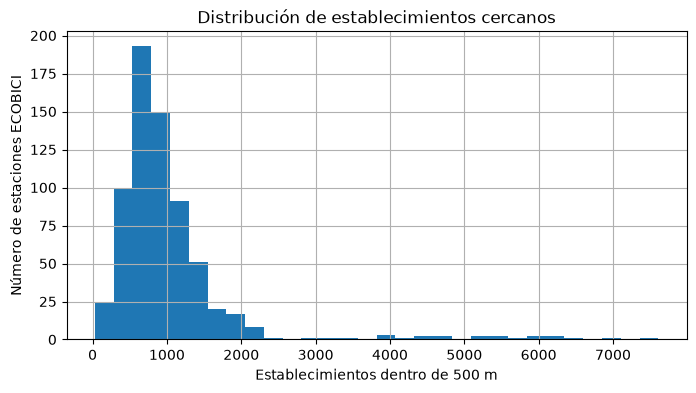

In [15]:
print(estaciones_geo["negocios_500m"].describe())

estaciones_geo["negocios_500m"].hist(
    bins=30,
    figsize=(8, 4)
)

plt.xlabel("Establecimientos dentro de 500 m")
plt.ylabel("Número de estaciones ECOBICI")
plt.title("Distribución de establecimientos cercanos")
plt.show()

In [16]:
personal_aprox = {
    "0 a 5 personas": 2.5,
    "6 a 10 personas": 8,
    "11 a 30 personas": 20.5,
    "31 a 50 personas": 40.5,
    "51 a 100 personas": 75.5,
    "101 a 250 personas": 175.5,
    "251 y más personas": 251
}

denue_geo["personal_aprox"] = denue_geo["per_ocu"].map(personal_aprox)

print("Valores sin asignar:", denue_geo["personal_aprox"].isna().sum())

Valores sin asignar: 0


In [17]:
negocios_cercanos["personal_aprox"] = negocios_cercanos["id"].map(
    denue_geo.set_index("id")["personal_aprox"]
)

personal_cercano = (
    negocios_cercanos
    .groupby("num_cicloe")["personal_aprox"]
    .sum()
)

estaciones_geo["personal_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(personal_cercano)
    .fillna(0)
)

estaciones_geo[
    ["num_cicloe", "negocios_500m", "personal_500m"]
].head()

,num_cicloe,negocios_500m,personal_500m
0,423,687,7297.0
1,437,466,6432.5
2,438,394,6792.5
3,439,618,11198.0
4,440,743,10221.5


In [18]:
estaciones_geo["personal_500m"].describe()

count      677.000000
mean     12332.046529
std       8198.495802
min        894.500000
25%       6350.500000
50%      10025.000000
75%      16041.000000
max      42572.500000
Name: personal_500m, dtype: float64

In [19]:
universidades = denue_geo[
    denue_geo["nombre_act"].str.contains(
        "educación superior",
        case=False,
        na=False
    )
]

universidades[
    ["codigo_act", "nombre_act"]
].drop_duplicates().sort_values("codigo_act")

,codigo_act,nombre_act
294171,611311,Escuelas de educación superior del sector privado
294153,611312,Escuelas de educación superior del sector público


In [20]:
codigos_universidades = [611311, 611312]

universidades = denue_geo[
    denue_geo["codigo_act"].isin(codigos_universidades)
].copy()

print("Establecimientos de educación superior:", len(universidades))

Establecimientos de educación superior: 791


In [21]:
universidades_cercanas = negocios_cercanos[
    negocios_cercanos["id"].isin(universidades["id"])
]

conteo_universidades = (
    universidades_cercanas
    .groupby("num_cicloe")
    .size()
)

estaciones_geo["universidades_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(conteo_universidades)
    .fillna(0)
    .astype(int)
)

In [22]:
print(estaciones_geo["universidades_500m"].describe())

estaciones_geo[
    ["num_cicloe", "negocios_500m",
     "personal_500m", "universidades_500m"]
].head()

count    677.000000
mean       3.677991
std        5.710962
min        0.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       47.000000
Name: universidades_500m, dtype: float64


,num_cicloe,negocios_500m,personal_500m,universidades_500m
0,423,687,7297.0,0
1,437,466,6432.5,1
2,438,394,6792.5,0
3,439,618,11198.0,1
4,440,743,10221.5,1


In [23]:
columnas = [
    "num_cicloe",
    "negocios_500m",
    "personal_500m",
    "universidades_500m"
]

variables_denue = estaciones_geo[columnas].copy()

variables_denue.to_csv(
    "../Data/Procesados/variables_DENUE_estaciones.csv",
    index=False
)

print("Dimensiones:", variables_denue.shape)
variables_denue.head()

Dimensiones: (677, 4)


,num_cicloe,negocios_500m,personal_500m,universidades_500m
0,423,687,7297.0,0
1,437,466,6432.5,1
2,438,394,6792.5,0
3,439,618,11198.0,1
4,440,743,10221.5,1


In [24]:
metro = gpd.read_file(
    "../Data/Info_transporte/stcmetro_shp/STC_Metro_estaciones_utm14n.shp"
)

metrobus = gpd.read_file(
    "../Data/Info_transporte/mb_shp/Metrobus_estaciones.shp"
)

print("Estaciones Metro:", len(metro))
print("Estaciones Metrobús:", len(metrobus))

print("\nCRS Metro:", metro.crs)
print("CRS Metrobús:", metrobus.crs)

print("\nTipos de geometría Metro:")
print(metro.geom_type.value_counts())

print("\nTipos de geometría Metrobús:")
print(metrobus.geom_type.value_counts())

Estaciones Metro: 195
Estaciones Metrobús: 324

CRS Metro: EPSG:4326
CRS Metrobús: EPSG:4326

Tipos de geometría Metro:
Point    195
Name: count, dtype: int64

Tipos de geometría Metrobús:
Point    324
Name: count, dtype: int64


In [25]:
print("Columnas Metro:")
print(metro.columns.tolist())

print("\nColumnas Metrobús:")
print(metrobus.columns.tolist())

display(metro.head())
display(metrobus.head())

Columnas Metro:
['SISTEMA', 'NOMBRE', 'LINEA', 'EST', 'CVE_EST', 'CVE_EOD17', 'TIPO', 'ALCALDIAS', 'AÑO', 'geometry']

Columnas Metrobús:
['SISTEMA', 'NOMBRE', 'LINEA', 'EST', 'CVE_EOD17', 'TIPO', 'ALCALDIAS', 'AÑO', 'CVE_EST', 'geometry']


,SISTEMA,NOMBRE,LINEA,EST,CVE_EST,CVE_EOD17,TIPO,ALCALDIAS,AÑO,geometry
0,STC Metro,Pantitlán,01,01,STC0101,05014,Terminal / Transbordo,Venustiano Carranza,1984,POINT Z (-99.07474 19.41633 0)
1,STC Metro,Zaragoza,01,02,STC0102,05020,Intermedia,Venustiano Carranza,1969,POINT Z (-99.08229 19.41192 0)
2,STC Metro,Gomez Farías,01,03,STC0103,05007,Intermedia,Venustiano Carranza,1969,POINT Z (-99.09021 19.41648 0)
3,STC Metro,Boulevard Puerto Aéreo,01,04,STC0104,05003,Intermedia,Venustiano Carranza,1969,POINT Z (-99.09626 19.41994 0)
4,STC Metro,Balbuena,01,05,STC0105,05001,Intermedia,Venustiano Carranza,1969,POINT Z (-99.10277 19.42336 0)


,SISTEMA,NOMBRE,LINEA,EST,CVE_EOD17,TIPO,ALCALDIAS,AÑO,CVE_EST,geometry
0,Metrobús,París,07,NaN,NaN,Servicio temporal,Cuauhtémoc,2023.0,NaN,POINT Z (-99.15591 19.43239 0)
1,Metrobús,Reforma,07,NaN,NaN,Servicio temporal,Cuauhtémoc,2023.0,NaN,POINT Z (-99.15854 19.43111 0)
2,Metrobús,Hamburgo,07,NaN,NaN,Servicio temporal,Cuauhtémoc,2023.0,NaN,POINT Z (-99.1628 19.42917 0)
3,Metrobús,El Ahuehuete,07,NaN,NaN,Servicio temporal,Cuauhtémoc,2023.0,NaN,POINT Z (-99.16506 19.42807 0)
4,Metrobús,El Ángel,07,NaN,NaN,Servicio temporal,Cuauhtémoc,2023.0,NaN,POINT Z (-99.16866 19.42642 0)


In [26]:
print("Tipos de estaciones Metro:")
print(metro["TIPO"].value_counts(dropna=False))

print("\nTipos de estaciones Metrobús:")
print(metrobus["TIPO"].value_counts(dropna=False))

print("\nCoordenadas duplicadas:")
print("Metro:", metro.geometry.duplicated().sum())
print("Metrobús:", metrobus.geometry.duplicated().sum())

Tipos de estaciones Metro:
TIPO
Intermedia               123
Transbordo                48
Terminal / Transbordo     12
Terminal                  12
Name: count, dtype: int64

Tipos de estaciones Metrobús:
TIPO
Intermedia               234
Transbordo                43
Terminal                  18
Servicio temporal         17
NaN                        6
Terminal / Transbordo      6
Name: count, dtype: int64

Coordenadas duplicadas:
Metro: 0
Metrobús: 0


In [27]:
metro_geo = metro.to_crs(epsg=32614)
metrobus_geo = metrobus.to_crs(epsg=32614)

print("Metro:", metro_geo.crs)
print("Metrobús:", metrobus_geo.crs)
print("ECOBICI:", estaciones_geo.crs)

Metro: EPSG:32614
Metrobús: EPSG:32614
ECOBICI: EPSG:32614


In [28]:
metro_geo = metro.to_crs(epsg=32614)

metrobus_geo = metrobus[
    metrobus["TIPO"] != "Servicio temporal"
].to_crs(epsg=32614)

print("Estaciones Metro:", len(metro_geo))
print("Estaciones Metrobús:", len(metrobus_geo))

Estaciones Metro: 195
Estaciones Metrobús: 307


In [29]:
metro_cercano = gpd.sjoin_nearest(
    estaciones_geo[["num_cicloe", "geometry"]],
    metro_geo[["geometry"]],
    how="left",
    distance_col="dist_metro"
)

distancias_metro = metro_cercano.groupby(
    "num_cicloe"
)["dist_metro"].min()

estaciones_geo["dist_metro"] = (
    estaciones_geo["num_cicloe"].map(distancias_metro)
)

In [30]:
metrobus_cercano = gpd.sjoin_nearest(
    estaciones_geo[["num_cicloe", "geometry"]],
    metrobus_geo[["geometry"]],
    how="left",
    distance_col="dist_metrobus"
)

distancias_metrobus = metrobus_cercano.groupby(
    "num_cicloe"
)["dist_metrobus"].min()

estaciones_geo["dist_metrobus"] = (
    estaciones_geo["num_cicloe"].map(distancias_metrobus)
)

In [31]:
estaciones_geo[
    ["dist_metro", "dist_metrobus"]
].describe()

,dist_metro,dist_metrobus
count,677.000000,677.000000
mean,615.519197,828.327571
std,408.808193,779.849788
min,20.426799,21.005765
25%,323.616814,268.225558
50%,530.016121,569.714934
75%,834.784834,1138.108173
max,2189.749932,4001.614328


In [32]:
print(
    estaciones_geo[
        ["dist_metro", "dist_metrobus"]
    ].isna().sum()
)

dist_metro       0
dist_metrobus    0
dtype: int64


In [33]:
ecobici_cercanas = gpd.sjoin(
    estaciones_geo[["num_cicloe", "geometry"]],
    buffers,
    how="inner",
    predicate="within",
    lsuffix="origen",
    rsuffix="vecina"
)

# Excluir la propia estación
ecobici_cercanas = ecobici_cercanas[
    ecobici_cercanas["num_cicloe_origen"]
    != ecobici_cercanas["num_cicloe_vecina"]
]

conteo_ecobici = (
    ecobici_cercanas
    .groupby("num_cicloe_origen")
    .size()
)

estaciones_geo["estaciones_ecobici_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(conteo_ecobici)
    .fillna(0)
    .astype(int)
)

In [34]:
print(
    estaciones_geo["estaciones_ecobici_500m"].describe()
)

estaciones_geo[
    ["num_cicloe", "estaciones_ecobici_500m"]
].head()

count    677.000000
mean       6.977843
std        3.291703
min        1.000000
25%        5.000000
50%        7.000000
75%        9.000000
max       18.000000
Name: estaciones_ecobici_500m, dtype: float64


,num_cicloe,estaciones_ecobici_500m
0,423,9
1,437,7
2,438,10
3,439,6
4,440,7


In [35]:
poblacion_geo = gpd.read_file(
    "../Data/Procesados/poblacion_geo.gpkg"
)

puntos_poblacion = poblacion_geo[
    ["CVEGEO", "POBTOT_num", "geometry"]
].copy()

puntos_poblacion["geometry"] = (
    puntos_poblacion.representative_point()
)

print("Manzanas:", len(puntos_poblacion))
print("CRS:", puntos_poblacion.crs)

Manzanas: 66449
CRS: EPSG:32614


In [36]:
poblacion_cercana = gpd.sjoin(
    puntos_poblacion,
    buffers,
    how="inner",
    predicate="within"
)

conteo_poblacion = (
    poblacion_cercana
    .groupby("num_cicloe")["POBTOT_num"]
    .sum()
)

estaciones_geo["poblacion_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(conteo_poblacion)
    .fillna(0)
)

In [37]:
estaciones_geo["poblacion_500m"].describe()

count      677.000000
mean     10286.707533
std       4498.163971
min         12.000000
25%       6976.000000
50%       9949.000000
75%      13041.000000
max      25544.000000
Name: poblacion_500m, dtype: float64

In [ ]:
from shapely.geometry import Point

centro = gpd.GeoSeries(
    [Point(-99.1332, 19.4326)], #Zócalo
    crs="EPSG:4326"
).to_crs(epsg=32614)

In [39]:
estaciones_geo["dist_centro"] = (
    estaciones_geo.geometry.distance(centro.iloc[0])
)

estaciones_geo["dist_centro"].describe()

count      677.000000
mean      5444.866607
std       2332.021589
min        147.230289
25%       3809.873894
50%       5329.601014
75%       7160.763680
max      10964.189767
Name: dist_centro, dtype: float64

In [40]:
ciclovias = gpd.read_file(
    "../Data/Info_infra_ciclista/infra_vial_ciclista.json"
)

print("Dimensiones:", ciclovias.shape)
print("CRS:", ciclovias.crs)

print("\nTipos de geometría:")
print(ciclovias.geom_type.value_counts())

print("\nColumnas:")
print(ciclovias.columns.tolist())

display(ciclovias.head())

Dimensiones: (80, 13)
CRS: EPSG:4326

Tipos de geometría:
LineString         78
MultiLineString     2
Name: count, dtype: int64

Columnas:
['ID_TRAMO', 'ID_PROY', 'NOMBRE', 'TIPO_IC', 'ALCALDIA', 'VIALIDAD', 'TIPO_VIA', 'ESTADO', 'EJECUTOR', 'A_INICIO', 'A_TERMINO', 'LONG_KM', 'geometry']


,ID_TRAMO,ID_PROY,NOMBRE,TIPO_IC,ALCALDIA,VIALIDAD,TIPO_VIA,ESTADO,EJECUTOR,A_INICIO,A_TERMINO,LONG_KM,geometry
0,1,1,Senderos Bosque de Chapultepec I Sección,Sendero compartido,Miguel Hidalgo,Gran Avenida,Secundaria,En operacion,Gobierno Central,ND,ND,2.04,"LINESTRING Z (-99.18006 19.42181 0, -99.17969 ..."
1,2,1,Senderos Bosque de Chapultepec I Sección,Sendero compartido,Miguel Hidalgo,Gran Avenida,Secundaria,En operacion,Gobierno Central,ND,ND,0.24,"LINESTRING Z (-99.18072 19.4221 0, -99.1805 19..."
2,3,1,Senderos Bosque de Chapultepec I Sección,Sendero compartido,Miguel Hidalgo,Avenida Grutas,Secundaria,En operacion,Gobierno Central,ND,ND,0.48,"MULTILINESTRING Z ((-99.18423 19.42157 0, -99...."
3,4,1,Senderos Bosque de Chapultepec I Sección,Sendero compartido,Miguel Hidalgo,Calzada Mahatma Gandhi,Secundaria,En operacion,Gobierno Central,ND,ND,0.25,"LINESTRING Z (-99.1805 19.42402 0, -99.1805 19..."
4,5,1,Senderos Bosque de Chapultepec I Sección,Sendero compartido,Miguel Hidalgo,Acceso Museo de Arte Moderno,Secundaria,En operacion,Gobierno Central,ND,ND,0.29,"LINESTRING Z (-99.18006 19.42181 0, -99.18006 ..."


In [41]:
print("Estados:")
print(ciclovias["ESTADO"].value_counts(dropna=False))

print("\nTipos de infraestructura:")
print(ciclovias["TIPO_IC"].value_counts(dropna=False))

print("\nLongitud total registrada (km):")
print(pd.to_numeric(ciclovias["LONG_KM"], errors="coerce").sum())

Estados:
ESTADO
En operacion    80
Name: count, dtype: int64

Tipos de infraestructura:
TIPO_IC
Sendero compartido    80
Name: count, dtype: int64

Longitud total registrada (km):
39.28


In [42]:
ciclovias = gpd.read_file(
    "../Data/Info_infra_ciclista/infraestructura_vial_ciclista/Infraestructura ciclista total.shp"
)

print("Dimensiones:", ciclovias.shape)
print("CRS:", ciclovias.crs)

print("\nEstados:")
print(ciclovias["ESTADO"].value_counts(dropna=False))

print("\nTipos de infraestructura:")
print(ciclovias["TIPO_IC"].value_counts(dropna=False))

print("\nLongitud total (km):")
print(pd.to_numeric(ciclovias["LONG_KM"], errors="coerce").sum())

Dimensiones: (651, 14)
CRS: EPSG:32614

Estados:
ESTADO
En operacion              514
Requiere mantenimiento     74
Fuera de servicio          63
Name: count, dtype: int64

Tipos de infraestructura:
TIPO_IC
Ciclovia                              231
Ciclocarril                           100
Carril bus bici                        98
Sendero compartido                     85
Ciclovia bidireccional                 61
Carril de prioridad ciclista           42
Infraestructura ciclista emergente     34
Name: count, dtype: int64

Longitud total (km):
580.6899999999999


In [43]:
ciclovias_activas = ciclovias[
    ciclovias["ESTADO"] == "En operacion"
].copy()

print("Tramos en operación:", len(ciclovias_activas))
print("CRS:", ciclovias_activas.crs)

Tramos en operación: 514
CRS: EPSG:32614


In [44]:
intersecciones = gpd.overlay(
    ciclovias_activas[["geometry"]],
    buffers[["num_cicloe", "geometry"]],
    how="intersection"
)

intersecciones["longitud_m"] = intersecciones.geometry.length

longitud_ciclovias = (
    intersecciones
    .groupby("num_cicloe")["longitud_m"]
    .sum()
)

estaciones_geo["infra_ciclista_500m"] = (
    estaciones_geo["num_cicloe"]
    .map(longitud_ciclovias)
    .fillna(0)
)

In [45]:
print(estaciones_geo["infra_ciclista_500m"].describe())

print(
    "Estaciones sin infraestructura cercana:",
    (estaciones_geo["infra_ciclista_500m"] == 0).sum()
)

count      677.000000
mean      2836.934938
std       1866.469536
min          0.000000
25%       1536.633544
50%       2706.740836
75%       4032.059524
max      10117.327480
Name: infra_ciclista_500m, dtype: float64
Estaciones sin infraestructura cercana: 55


In [46]:
columnas = [
    "num_cicloe",
    "alcaldia",
    "latitud",
    "longitud",
    "poblacion_500m",
    "negocios_500m",
    "personal_500m",
    "dist_metro",
    "dist_metrobus",
    "infra_ciclista_500m",
    "estaciones_ecobici_500m",
    "universidades_500m",
    "dist_centro"
]

variables_estaciones = estaciones_geo[columnas].copy()

print("Dimensiones:", variables_estaciones.shape)
print("\nValores faltantes:")
print(variables_estaciones.isna().sum())

variables_estaciones.to_csv(
    "../Data/Procesados/variables_estaciones_ECOBICI.csv",
    index=False
)

Dimensiones: (677, 13)

Valores faltantes:
num_cicloe                 0
alcaldia                   0
latitud                    0
longitud                   0
poblacion_500m             0
negocios_500m              0
personal_500m              0
dist_metro                 0
dist_metrobus              0
infra_ciclista_500m        0
estaciones_ecobici_500m    0
universidades_500m         0
dist_centro                0
dtype: int64
